# 7.1.- Autoencoder Básico con MNIST

En este notebook construiremos un **autoencoder simple** que aprenderá a **comprimir (codificar)** y **reconstruir (decodificar)** imágenes del dataset MNIST.  
El objetivo es que el modelo aprenda una **representación latente** de las imágenes, sin supervisión directa (no se usan etiquetas).

**Objetivos:**
1. Cargar y normalizar el dataset MNIST.
2. Construir la arquitectura del autoencoder (encoder + decoder).
3. Entrenar el modelo para minimizar el error de reconstrucción.
4. Visualizar los resultados.

In [42]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(33)
tf.random.set_seed(33)

## Carga y preprocesamiento de los datos

Usaremos el dataset **MNIST**, que contiene imágenes de dígitos escritos a mano (0–9).  
Cada imagen tiene tamaño **28x28 píxeles** y valores de intensidad entre 0 y 255, por lo que normalizaremos los datos al rango `[0, 1]`.

In [34]:
# Cargar dataset MNIST
(X_train, _), (X_test, _) = tf.keras.datasets.mnist.load_data()

# Normalizar al rango [0,1] y redimensionar
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Añadir dimensión de canal (necesario para Conv2D)
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Dataset cargado correctamente.")
print(f"Tamaño del conjunto de entrenamiento: {X_train.shape}")
print(f"Tamaño del conjunto de prueba: {X_test.shape}")

Dataset cargado correctamente.
Tamaño del conjunto de entrenamiento: (60000, 28, 28, 1)
Tamaño del conjunto de prueba: (10000, 28, 28, 1)


## Definición del modelo

El **autoencoder** es una red neuronal compuesta por dos partes principales:

- **Encoder (codificador):** recibe la imagen original y la transforma en una representación comprimida (de menor dimensión).  
- **Decoder (decodificador):** toma esa representación comprimida e intenta reconstruir la imagen original.

En este caso, construiremos un **autoencoder denso** (no convolucional), donde:
- Aplanaremos las imágenes de 28x28 píxeles en vectores de 784 elementos.
- Reduciremos progresivamente la dimensionalidad en el encoder.
- Reconstruiremos la imagen en el decoder hasta volver a la forma original.

Usaremos **funciones de activación ReLU** en las capas intermedias y una **sigmoide** en la salida, ya que los valores están normalizados entre 0 y 1.

In [35]:
autoencoder = models.Sequential([
    layers.Flatten(input_shape=(28, 28, 1)),   # Entrada
    
    # Encoder
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),       # Cuello de botella (espacio latente)
    
    # Decoder
    layers.Dense(64, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(28*28, activation='sigmoid'),
    
    layers.Reshape((28, 28, 1))                # Salida reconstruida
])

autoencoder.compile(optimizer='adam', loss='binary_crossentropy')
autoencoder.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento del modelo

Durante el entrenamiento, el autoencoder intentará **reducir el error de reconstrucción** entre la imagen de entrada y la imagen reconstruida.

- Como no hay etiquetas, el modelo se entrena con `X_train` como **entrada y salida simultáneamente**.
- Se utiliza la **función de pérdida binary crossentropy**, adecuada cuando los valores están en el rango [0, 1].
- El optimizador **Adam** ajustará los pesos automáticamente para mejorar la reconstrucción.

Al final del entrenamiento, el modelo debería ser capaz de generar imágenes que se asemejen bastante a las originales, aunque con cierta pérdida de detalle.

In [36]:
history = autoencoder.fit(
    X_train, X_train,            # Entradas y salidas son las mismas
    epochs=20,                   # Número de épocas
    batch_size=256,              # Tamaño de lote
    shuffle=True,                # Barajar los datos en cada época
    validation_data=(X_test, X_test)  # Validación no supervisada
)

Epoch 1/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - loss: 0.3474 - val_loss: 0.1730
Epoch 2/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1621 - val_loss: 0.1352
Epoch 3/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1332 - val_loss: 0.1220
Epoch 4/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1215 - val_loss: 0.1145
Epoch 5/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1149 - val_loss: 0.1098
Epoch 6/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1105 - val_loss: 0.1065
Epoch 7/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1074 - val_loss: 0.1042
Epoch 8/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.1051 - val_loss: 0.1024
Epoch 9/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1033 - val_loss: 0.1008
Epoch 10/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1016 - val_loss: 0.0993
Epoch 11/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1001 - val_loss: 0.0977
Epoch 12/20
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/ste

## Evolución del entrenamiento

Durante el proceso de entrenamiento, el autoencoder va reduciendo progresivamente la **pérdida de reconstrucción**.  
Para evaluar su progreso, representaremos la evolución del **loss** tanto en el conjunto de entrenamiento como en el de validación.

Una curva suave y decreciente indica que el modelo está aprendiendo a reconstruir correctamente las imágenes.  
Si la pérdida de validación se mantiene estable y no diverge de la de entrenamiento, significa que el modelo **no está sobreajustando**.

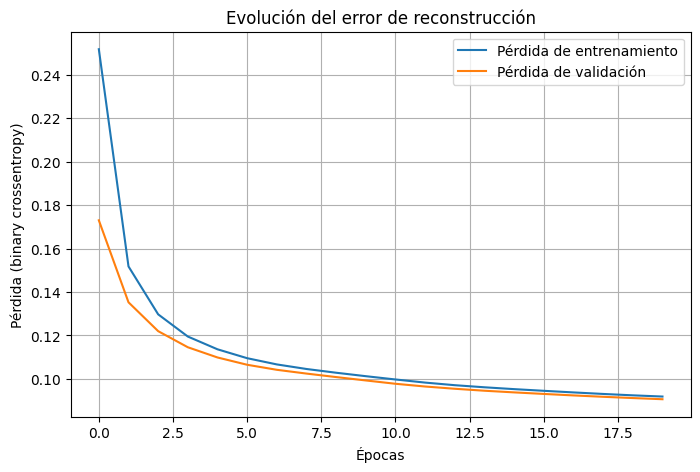

In [37]:
# Visualizar las curvas de pérdida
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Pérdida de entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida de validación')
plt.title('Evolución del error de reconstrucción')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (binary crossentropy)')
plt.legend()
plt.grid(True)
plt.show()

## Resultados: reconstrucción de imágenes

Una vez entrenado el autoencoder, podemos probarlo con nuevas imágenes del conjunto de prueba.  
El modelo recibirá la imagen, la **codificará en su espacio latente** y luego la **reconstruirá**.

A continuación mostraremos algunas comparaciones entre:
- **Fila superior:** imágenes originales.  
- **Fila inferior:** reconstrucciones generadas por el autoencoder.

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 824us/step


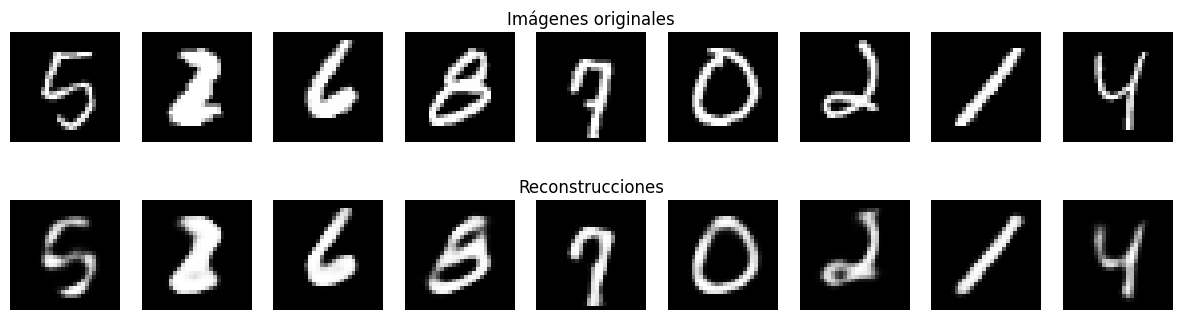

In [40]:
# Generar reconstrucciones
decoded_imgs = autoencoder.predict(X_test)

# Seleccionar índices aleatorios del conjunto de prueba
n = 9  # Número de ejemplos a visualizar
indices = np.random.choice(len(X_test), n, replace=False)

# Mostrar resultados
plt.figure(figsize=(15, 4))

for i, idx in enumerate(indices):
    # Imagen original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == n // 2:
        ax.set_title("Imágenes originales")

    # Imagen reconstruida
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[idx].reshape(28, 28), cmap="gray")
    plt.axis("off")
    if i == n // 2:
        ax.set_title("Reconstrucciones")

plt.show()